# Multi-asset figures (10 banks, return state)

Plots the results of `experiments/run_multiasset.py`. No training (figure 12 loads one saved model). Figures go to `results/multi_asset/figures`, LaTeX tables to `results/multi_asset/tables`.

In [1]:
import sys
import json
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "markov").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from markov.data import TICKERS, load_bank, splits_by_horizon, returns, return_states, forward_labels, quantile_edges, to_bins
from markov.models import make_model
from markov.metrics import counts

RES = ROOT / "results/multi_asset"
FIG = RES / "figures"
TAB = RES / "tables"
HORIZONS = [1, 5, 10, 21, 63]
BINS = [4, 10, 20, 35, 55]
REGIMES = ["full", "macro_only", "own_only", "other_banks_only"]
COLORS = dict(zip(TICKERS, plt.cm.tab10.colors))
REGIME_COLORS = dict(zip(REGIMES, plt.cm.tab10.colors))
STRESS = [("COVID", "2020-02-20", "2020-04-30"), ("SVB", "2023-03-08", "2023-03-31")]
W1, W2 = 3.5, 7.0  # single and double column widths in inches
plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.color": "#e0e0e0", "grid.linewidth": 0.5,
                     "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight"})


def save(fig, stem):
    FIG.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG / f"{stem}.pdf")
    fig.savefig(FIG / f"{stem}.png")
    plt.show()


def shade(ax):
    for _, a, b in STRESS:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), alpha=0.12, color="gray", zorder=0)


def load(exp):
    return pd.concat([pd.read_csv(RES / t / exp / "nll_metrics.csv").assign(ticker=t) for t in TICKERS
                      if (RES / t / exp / "nll_metrics.csv").exists()], ignore_index=True)


nll_A, nll_C, nll_E = load("baseline"), load("swa_bestsigma"), load("conditioning_regime")
nll_D = pd.read_csv(RES / "JPM/higher_order/nll_metrics.csv")
cross = pd.read_csv(RES / "cross_asset_diagnostics.csv", parse_dates=["date"])
sweep = pd.read_csv(RES / "JPM/sigma_sweep/sweep_h1.csv")
print({k: len(v) for k, v in dict(A=nll_A, C=nll_C, D=nll_D, E=nll_E, cross=cross).items()})

{'A': 1500, 'C': 1500, 'D': 60, 'E': 240, 'cross': 9280}


## Fig 1: share of sparse cells in the empirical 1-step count matrix vs N

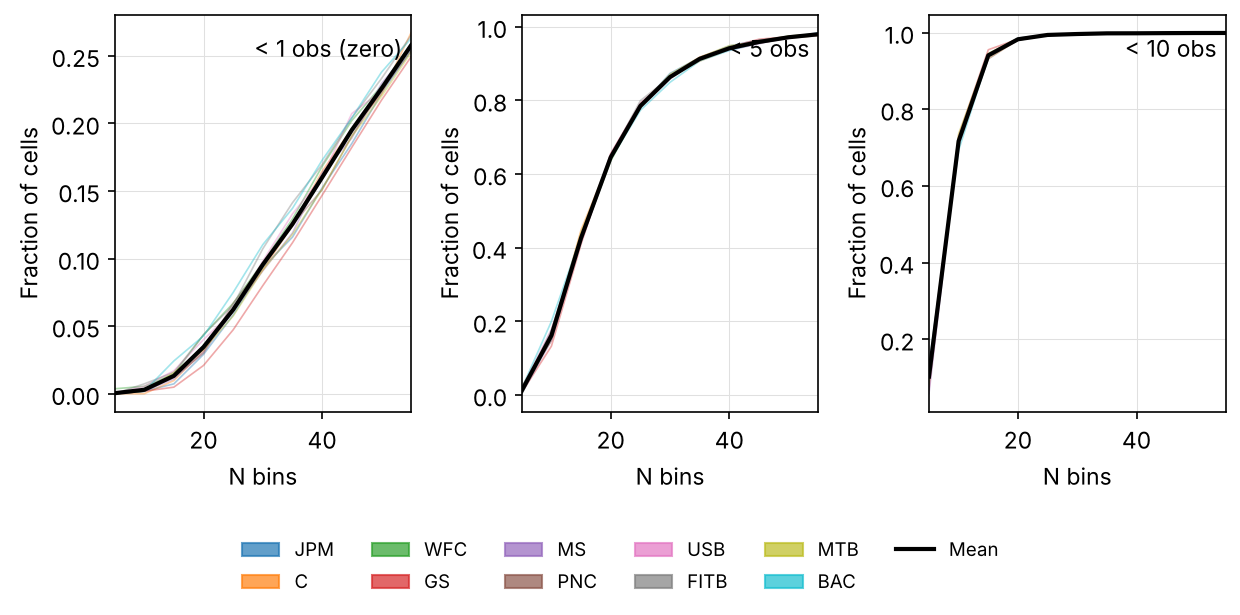

In [2]:
N_range = list(range(5, 60, 5))
curves = {}
for t in TICKERS:
    prices, _, _ = load_bank(t)
    tr = splits_by_horizon(len(prices) - 1, [1])[1]["idx_train"]
    X, n_x, _ = return_states(prices, 55, len(tr))
    R = returns(prices[1:], 1)[tr]
    for N in N_range:
        n, edges = quantile_edges(R, N)
        C = counts(X[tr], to_bins(R, edges), n_x, n)
        for k in [1, 5, 10]:
            curves.setdefault((t, k), []).append(float((C < k).mean()))

fig, axes = plt.subplots(1, 3, figsize=(W2 * 1.2, W1))
for ax, k, label in zip(axes, [1, 5, 10], ["< 1 obs (zero)", "< 5 obs", "< 10 obs"]):
    for t in TICKERS:
        ax.plot(N_range, curves[(t, k)], color=COLORS[t], alpha=0.4, lw=0.8)
    ax.plot(N_range, np.mean([curves[(t, k)] for t in TICKERS], axis=0), color="black", lw=2)
    ax.set(xlabel="N bins", ylabel="Fraction of cells", xlim=(N_range[0], N_range[-1]))
    ax.text(0.97, 0.95, label, transform=ax.transAxes, ha="right", va="top")
handles = [mpatches.Patch(color=COLORS[t], label=t, alpha=0.7) for t in TICKERS] + [plt.Line2D([0], [0], color="black", lw=2, label="Mean")]
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.18), frameon=False, fontsize=9)
fig.tight_layout()
save(fig, "fig1")

## Fig 2: test NLL vs horizon per bank (SWA run, N=55)

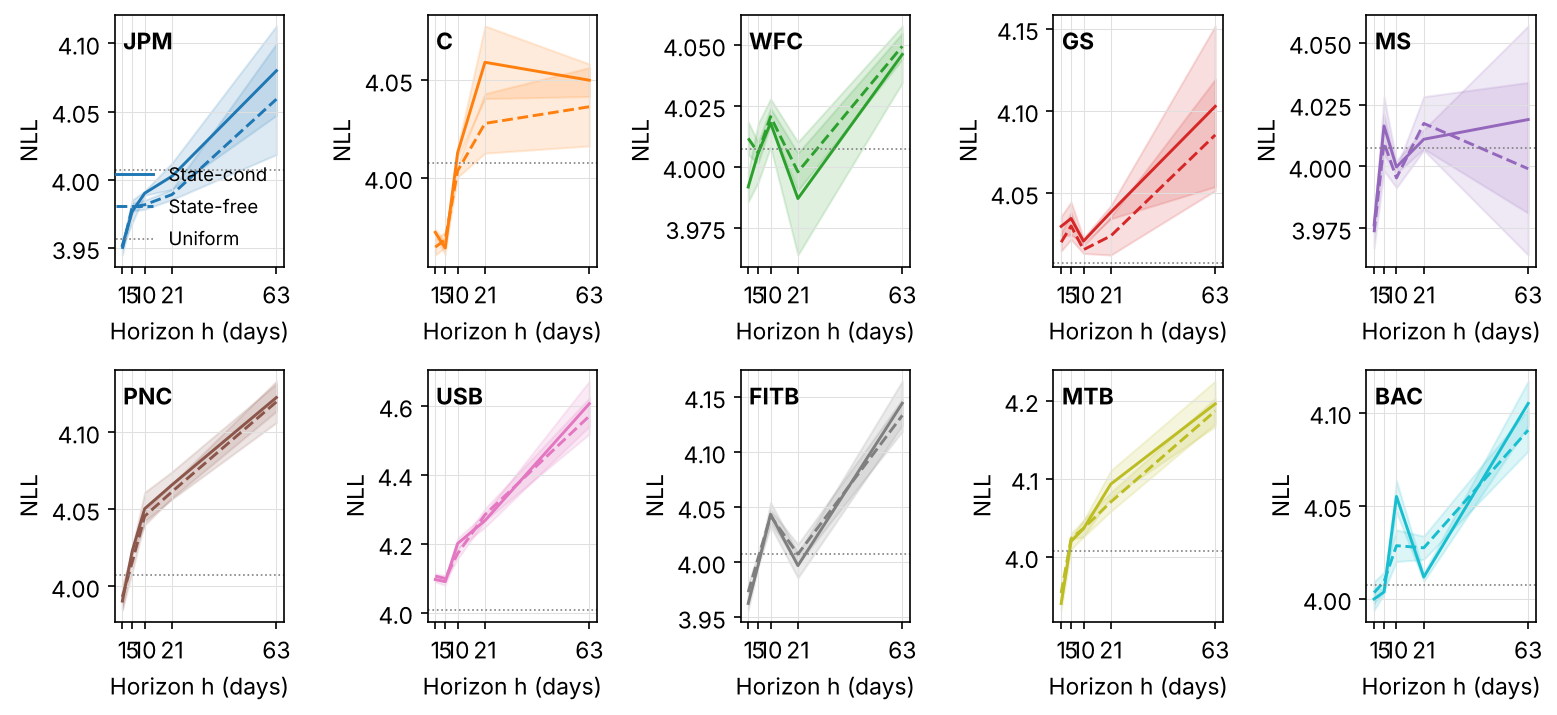

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(W2 * 1.5, W2 * 0.7))
for ax, t in zip(axes.flat, TICKERS):
    for kind, ls, label in [("state_cond", "-", "State-cond"), ("state_free", "--", "State-free")]:
        g = nll_C[(nll_C.ticker == t) & (nll_C.N == 55) & (nll_C.model == kind)].groupby("h").nll_test.agg(["mean", "std"])
        ax.plot(g.index, g["mean"], ls=ls, color=COLORS[t], lw=1.4, label=label)
        ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"], alpha=0.15, color=COLORS[t])
    ax.axhline(np.log(55), color="gray", lw=0.8, ls=":", label="Uniform")
    ax.set(xlabel="Horizon h (days)", ylabel="NLL", xticks=HORIZONS)
    ax.text(0.05, 0.95, t, transform=ax.transAxes, fontweight="bold", va="top")
axes[0, 0].legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
save(fig, "fig2")

## Fig 3: test NLL vs number of bins (h=1)

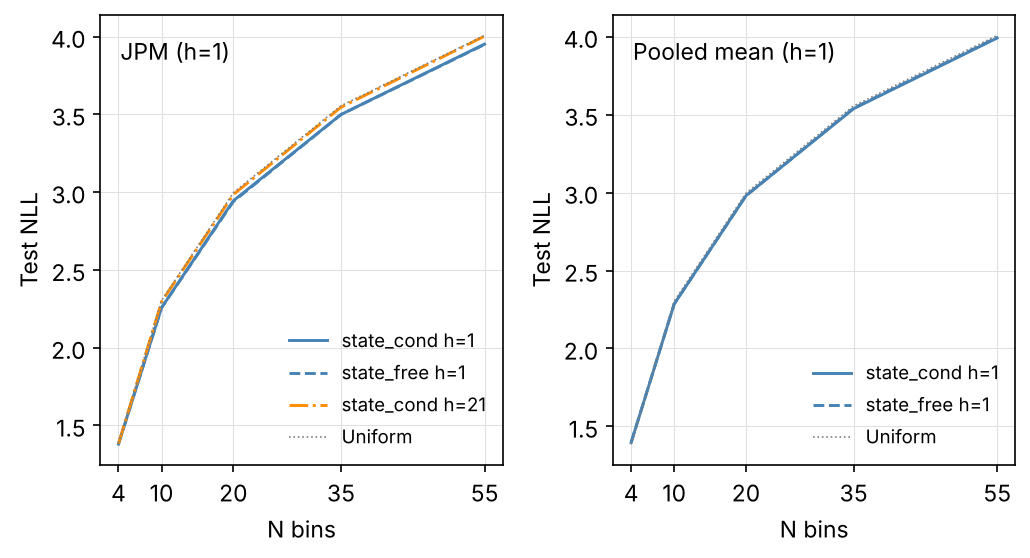

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(W2, W1 * 1.1))
for ax, (label, df) in zip(axes, [("JPM (h=1)", nll_C[(nll_C.ticker == "JPM") & (nll_C.h == 1)]), ("Pooled mean (h=1)", nll_C[nll_C.h == 1])]):
    for kind, ls in [("state_cond", "-"), ("state_free", "--")]:
        g = df[df.model == kind].groupby("N").nll_test.mean()
        ax.plot(g.index, g.values, ls=ls, color="steelblue", lw=1.4, label=f"{kind} h=1")
    if label.startswith("JPM"):
        g = nll_C[(nll_C.ticker == "JPM") & (nll_C.h == 21) & (nll_C.model == "state_cond")].groupby("N").nll_test.mean()
        ax.plot(g.index, g.values, ls="-.", color="darkorange", lw=1.4, label="state_cond h=21")
    ax.plot(BINS, np.log(BINS), ls=":", color="gray", lw=0.8, label="Uniform")
    ax.set(xlabel="N bins", ylabel="Test NLL", xticks=BINS)
    ax.text(0.05, 0.95, label, transform=ax.transAxes, va="top")
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
save(fig, "fig3")

## Fig 4: conditioning on the last k states (JPM, N=55)

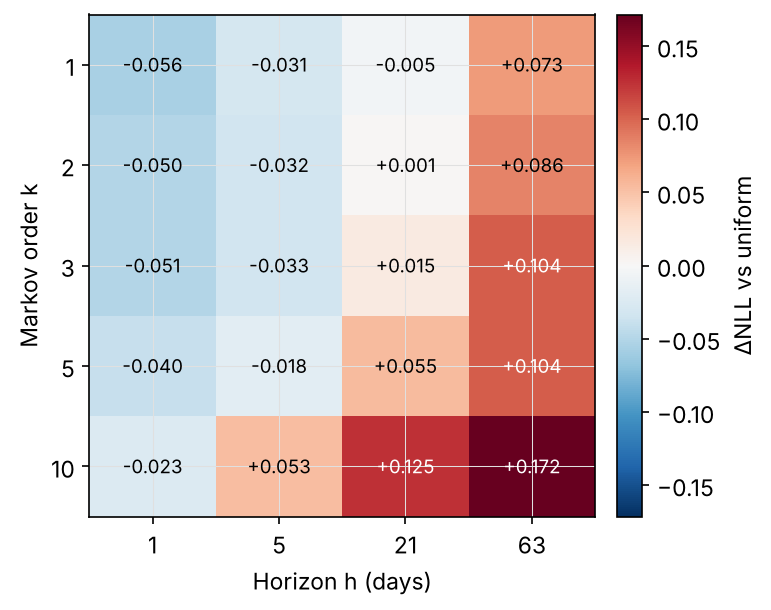

In [5]:
d = nll_D.assign(k=nll_D.model.str.extract(r"ho_k(\d+)", expand=False).astype(int))
heat = d.groupby(["k", "h"]).delta_marginal.mean().unstack("h")
v = np.nanmax(np.abs(heat.values))
fig, ax = plt.subplots(figsize=(W1 * 1.5, W1 * 1.2))
im = ax.imshow(heat.values, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
ax.set(xticks=range(heat.shape[1]), xticklabels=heat.columns, yticks=range(heat.shape[0]), yticklabels=heat.index,
       xlabel="Horizon h (days)", ylabel="Markov order k")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:+.3f}", ha="center", va="center", fontsize=9,
                color="white" if abs(heat.values[i, j]) > 0.6 * v else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("ΔNLL vs uniform")
fig.tight_layout()
save(fig, "fig4")

## Fig 5: feature subsets (h=1 and h=21, N=55)

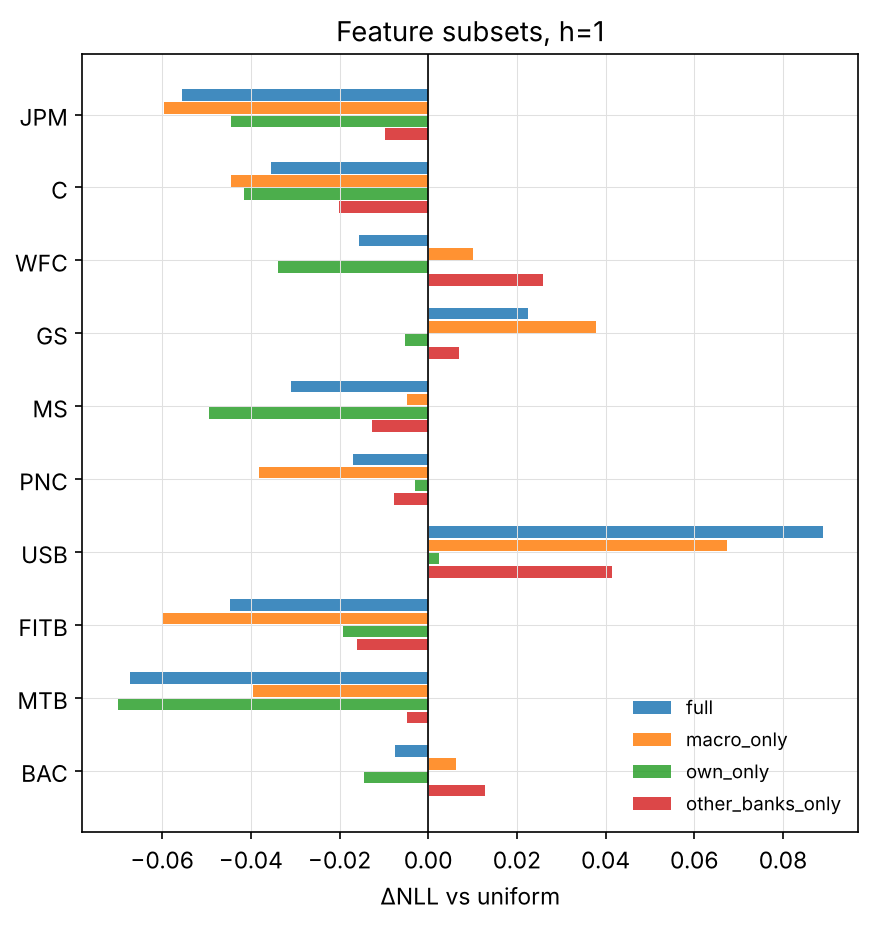

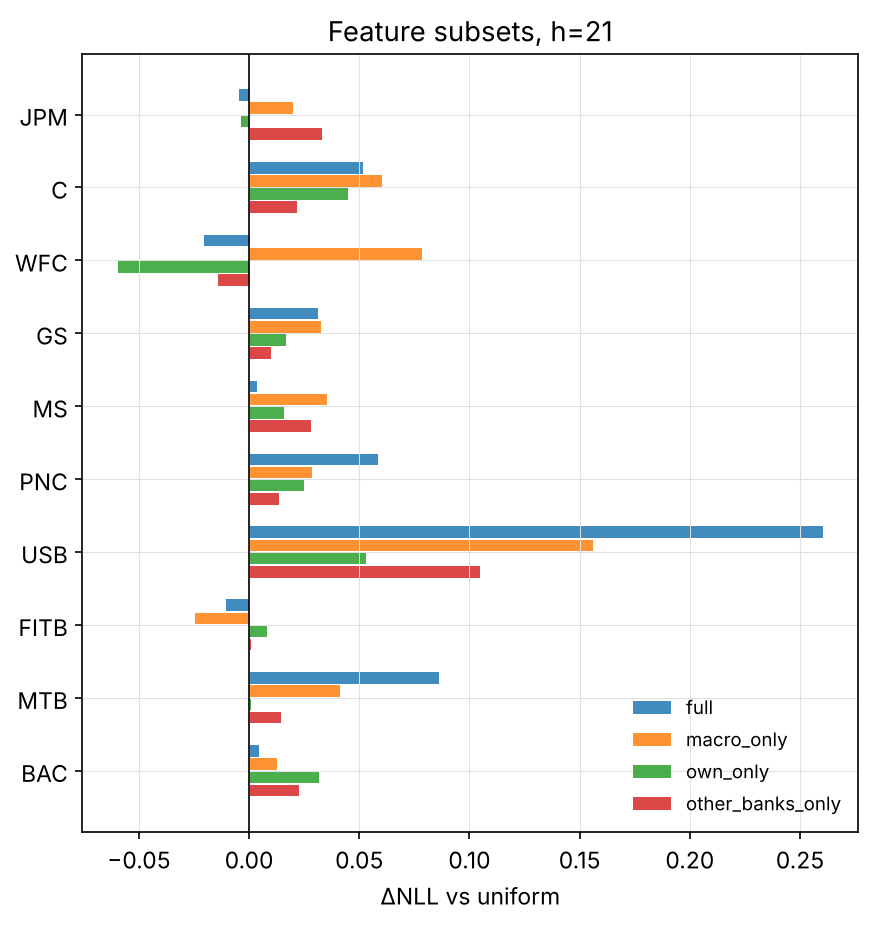

In [6]:
for h, stem in [(1, "fig5a"), (21, "fig5b")]:
    g = nll_E[nll_E.h == h].assign(regime=lambda x: x.model.str.replace("state_cond_", "")).groupby(["ticker", "regime"]).delta_marginal.mean()
    fig, ax = plt.subplots(figsize=(W2 * 0.85, W2 * 0.9))
    y = np.arange(len(TICKERS))
    for i, r in enumerate(REGIMES):
        ax.barh(y + (i - 1.5) * 0.18, [g.get((t, r), np.nan) for t in TICKERS], height=0.16, color=REGIME_COLORS[r], label=r, alpha=0.85)
    ax.axvline(0, color="black", lw=0.8)
    ax.set(yticks=y, yticklabels=TICKERS, xlabel="ΔNLL vs uniform", title=f"Feature subsets, h={h}")
    ax.legend(loc="lower right", frameon=False, fontsize=9)
    ax.invert_yaxis()
    fig.tight_layout()
    save(fig, stem)

## Fig 6: operator snapshots for three banks (calm, bearish, bullish days, seed 42)

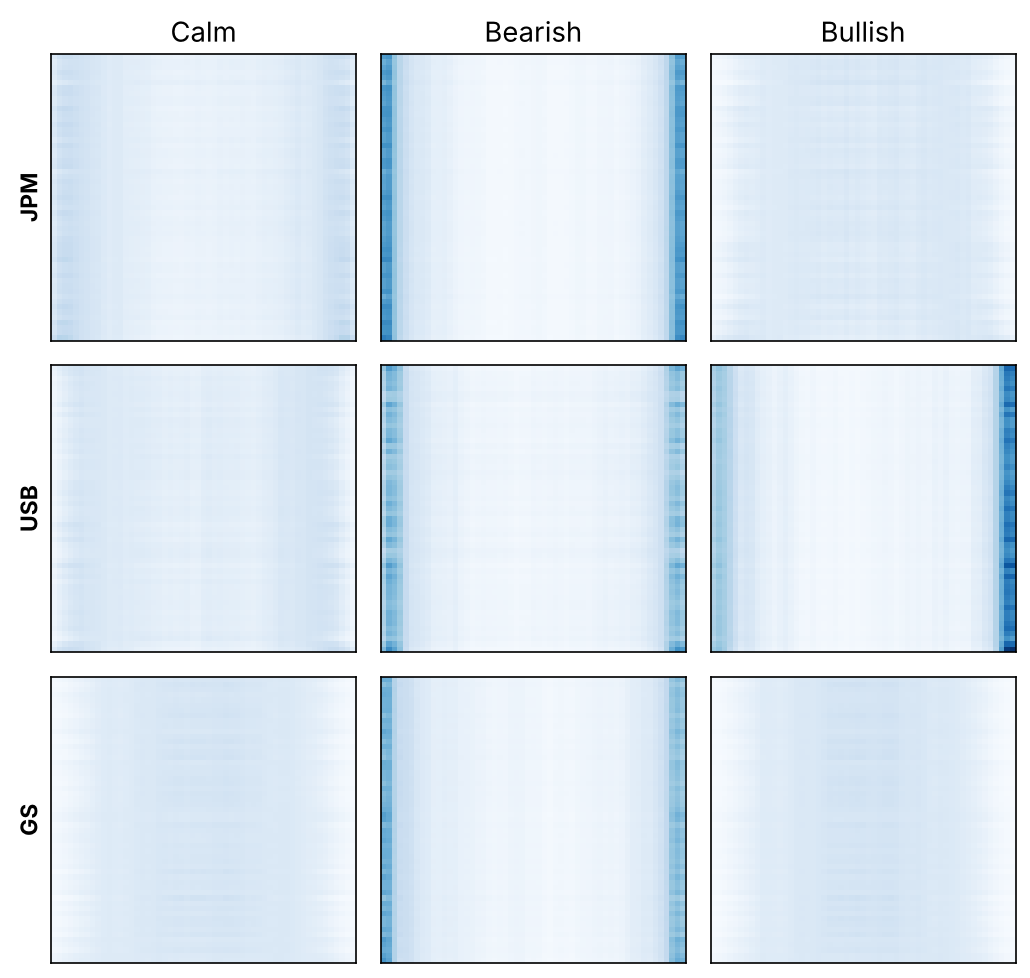

In [7]:
by_t = nll_C[(nll_C.h == 1) & (nll_C.N == 55) & (nll_C.model == "state_cond")].groupby("ticker").delta_marginal.mean()
snap = ["JPM"] + [t for t in [by_t.abs().idxmax()] + by_t[by_t > 0].index.tolist() + TICKERS if t != "JPM"]
snap = list(dict.fromkeys(snap))[:3]
mats = {(t, s): np.load(RES / t / "swa_bestsigma/snapshots" / f"operator_snapshot_{s}_seed42.npy") for t in snap for s in ["calm", "bearish", "bullish"]}
vmax = max(m.max() for m in mats.values())
fig, axes = plt.subplots(3, 3, figsize=(W2, W2 * 0.95))
for i, t in enumerate(snap):
    for j, s in enumerate(["calm", "bearish", "bullish"]):
        axes[i, j].imshow(mats[(t, s)], cmap="Blues", vmin=0, vmax=vmax, aspect="auto", origin="lower")
        axes[i, j].set(xticks=[], yticks=[])
        axes[0, j].set_title(s.capitalize())
    axes[i, 0].set_ylabel(t, fontweight="bold")
fig.tight_layout()
save(fig, "fig6")

## Figs 7 and 8: row entropy and h=5 CK error over the test period, all banks

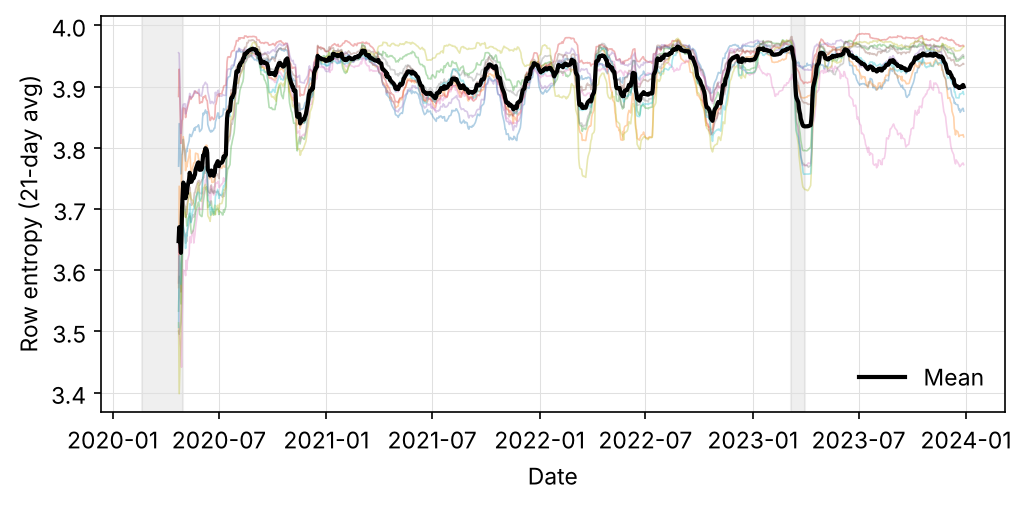

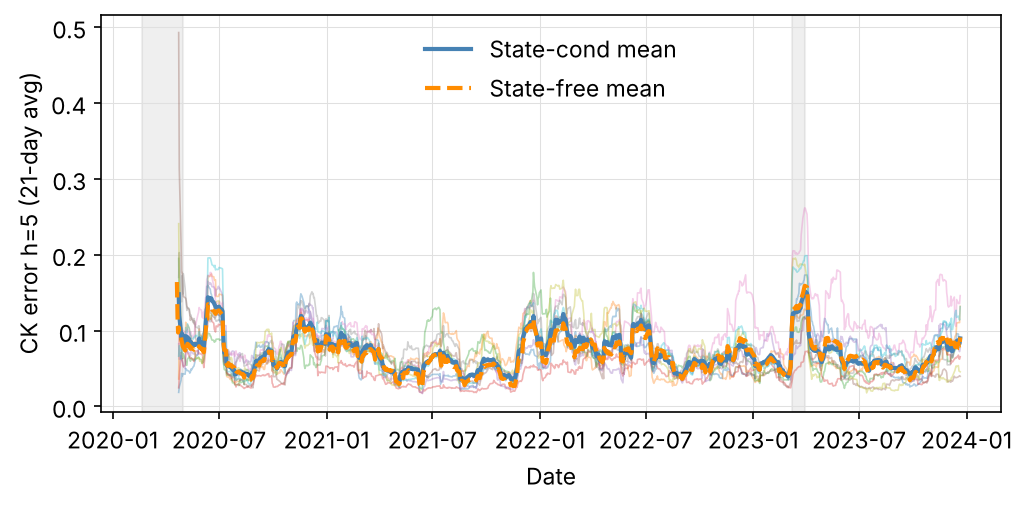

In [8]:
for col, stem, ylabel in [("row_entropy", "fig7", "Row entropy (21-day avg)"), ("ck_error_h5", "fig8", "CK error h=5 (21-day avg)")]:
    pivot = cross.pivot_table(index="date", columns="ticker", values=col).rolling(21, min_periods=1).mean()
    fig, ax = plt.subplots(figsize=(W2, W1))
    for t in TICKERS:
        ax.plot(pivot.index, pivot[t], color=COLORS[t], alpha=0.35, lw=0.8)
    ax.plot(pivot.index, pivot.mean(axis=1), color="black" if stem == "fig7" else "steelblue", lw=2,
            label="Mean" if stem == "fig7" else "State-cond mean")
    if stem == "fig8":
        sf = []
        for t in TICKERS:
            s = [pd.read_csv(RES / t / f"swa_bestsigma/ck_ts_state_free_h5_N55_seed{seed}.csv", parse_dates=["date"]).set_index("date").ck_kl
                 for seed in [42, 7, 123]]
            sf.append(pd.concat(s, axis=1).mean(axis=1).rolling(21, min_periods=1).mean())
        ax.plot(sf[0].index, pd.concat(sf, axis=1).mean(axis=1), color="darkorange", lw=2, ls="--", label="State-free mean")
    shade(ax)
    ax.set(xlabel="Date", ylabel=ylabel)
    ax.legend(frameon=False)
    fig.tight_layout()
    save(fig, stem)

## Fig 9: correlation of row entropy across banks (test period)

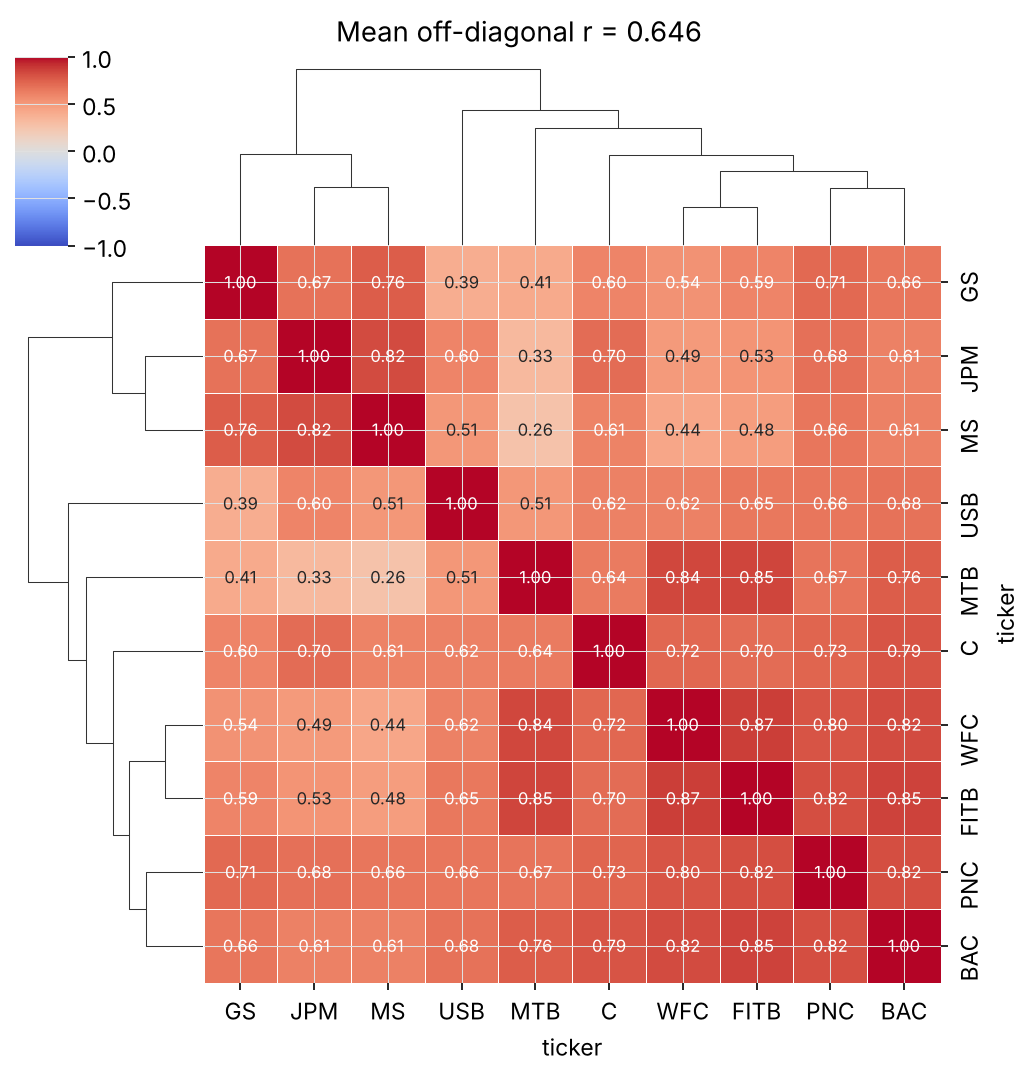

mean pairwise correlation of row entropy: 0.646


In [9]:
corr = cross.pivot_table(index="date", columns="ticker", values="row_entropy")[TICKERS].corr()
mean_corr = corr.values[np.triu_indices(10, 1)].mean()
g = sns.clustermap(corr, cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".2f", linewidths=0.4, figsize=(W2, W2), annot_kws={"size": 8})
g.fig.suptitle(f"Mean off-diagonal r = {mean_corr:.3f}", y=1.02)
g.fig.savefig(FIG / "fig9.pdf")
g.fig.savefig(FIG / "fig9.png")
plt.show()
print(f"mean pairwise correlation of row entropy: {mean_corr:.3f}")

## Fig 10: state dependence (row heterogeneity) per bank over time

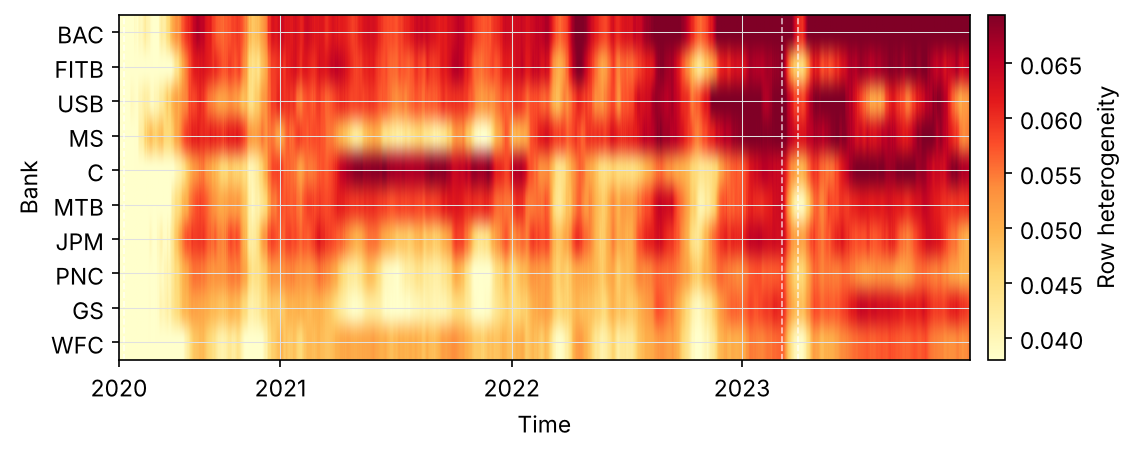

In [10]:
pivot = cross.pivot_table(index="date", columns="ticker", values="row_heterogeneity").rolling(21, min_periods=1).mean()
order = pivot.mean().sort_values(ascending=False).index
mat = pivot[order].T.values
fig, ax = plt.subplots(figsize=(W2 * 1.1, W1 * 0.9))
im = ax.imshow(mat, aspect="auto", cmap="YlOrRd", vmin=np.nanpercentile(mat, 5), vmax=np.nanpercentile(mat, 95))
years = sorted({d.year for d in pivot.index})
ax.set(yticks=range(len(order)), yticklabels=order, xlabel="Time", ylabel="Bank",
       xticks=[np.searchsorted(pivot.index, pd.Timestamp(f"{y}-01-01")) for y in years], xticklabels=years)
for _, a, b in STRESS:
    for x in [a, b]:
        ax.axvline(np.searchsorted(pivot.index, pd.Timestamp(x)), color="white", lw=0.8, ls="--", alpha=0.7)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02).set_label("Row heterogeneity")
fig.tight_layout()
save(fig, "fig10")

## Fig 11: state dependence on low vs high VIX days (test period, state_cond h=1 N=55)

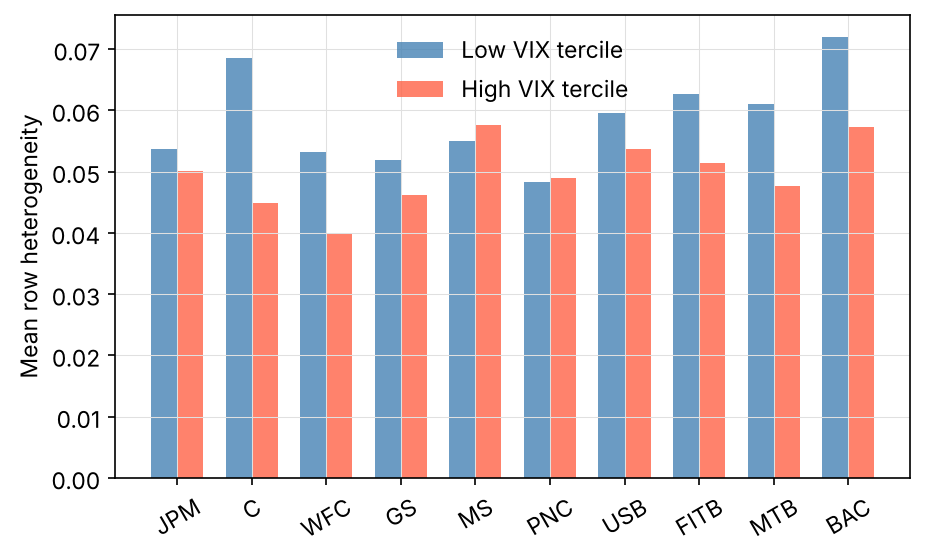

In [11]:
rows = []
for t in TICKERS:
    prices, F, cols = load_bank(t)
    te = splits_by_horizon(len(prices) - 1, [1])[1]["idx_test"]
    vix = F[te, cols.index("VIXCLS")]
    lo, hi = vix <= np.percentile(vix, 33.3), vix >= np.percentile(vix, 66.7)
    rh = [pd.read_csv(RES / t / f"swa_bestsigma/operator_ts_state_cond_h1_N55_seed{s}.csv").row_heterogeneity.values for s in [42, 7, 123]]
    rows.append({"ticker": t, "low_vix": np.mean([r[lo].mean() for r in rh]), "high_vix": np.mean([r[hi].mean() for r in rh])})
vix = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(W2 * 0.9, W1 * 1.1))
x = np.arange(len(vix))
ax.bar(x - 0.175, vix.low_vix, 0.35, label="Low VIX tercile", color="steelblue", alpha=0.8)
ax.bar(x + 0.175, vix.high_vix, 0.35, label="High VIX tercile", color="tomato", alpha=0.8)
ax.set(xticks=x, ylabel="Mean row heterogeneity")
ax.set_xticklabels(vix.ticker, rotation=30)
ax.legend(frameon=False)
fig.tight_layout()
save(fig, "fig11")

## Fig 12: feature importance for JPM (h=1, N=55): NLL increase when one feature is zeroed

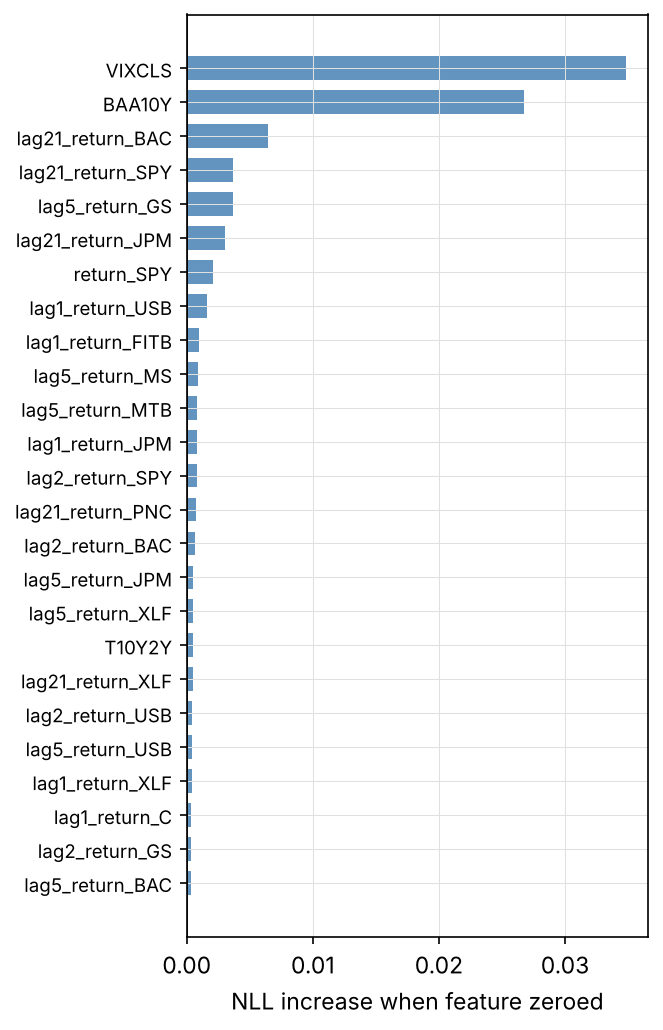

In [12]:
prices, F, cols = load_bank("JPM")
sp = splits_by_horizon(len(prices) - 1, [1])
X, n_x, _ = return_states(prices, 55, len(sp[1]["idx_train"]))
c = forward_labels(prices, sp, [55])[(1, 55)]
best_sigma = float(sweep.groupby("sigma").nll_val.mean().idxmin())
model = make_model("state_cond", F.shape[1], n_x, 55)
model.load_state_dict(torch.load(RES / f"weights/Cext_s{best_sigma}_JPM_state_cond_h1_N55_seed42.pt", map_location="cpu"))
model.eval()
te = c["idx_test"]
f, x, y = torch.tensor(F[te]), torch.tensor(X[te]), torch.tensor(c["y_all"][te])


def nll(f):
    with torch.no_grad():
        return float(-torch.log_softmax(model(f, x), dim=1)[torch.arange(len(y)), y].mean())


base = nll(f)
gain = sorted(((name, nll(f.index_fill(1, torch.tensor([i]), 0.0)) - base) for i, name in enumerate(cols)), key=lambda z: -z[1])[:25]
fig, ax = plt.subplots(figsize=(W1 * 1.3, W2))
ax.barh(np.arange(25)[::-1], [g for _, g in gain], height=0.7, color="steelblue", alpha=0.85)
ax.set(yticks=np.arange(25)[::-1], xlabel="NLL increase when feature zeroed")
ax.set_yticklabels([n for n, _ in gain], fontsize=9)
ax.axvline(0, color="black", lw=0.8)
fig.tight_layout()
save(fig, "fig12")

## LaTeX tables

In [13]:
def latex(df, caption, label, path):
    lines = [r"\begin{table}[ht]", r"\centering", f"\\caption{{{caption}}}", f"\\label{{{label}}}",
             r"\begin{tabular}{l" + "r" * (df.shape[1] - 1) + "}", r"\toprule", " & ".join(map(str, df.columns)) + r" \\", r"\midrule"]
    lines += [" & ".join(f"{v:.4f}" if isinstance(v, float) else str(v) for v in row) + r" \\" for row in df.itertuples(index=False)]
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    TAB.mkdir(parents=True, exist_ok=True)
    (TAB / path).write_text("\n".join(lines))


latex(nll_A[(nll_A.N == 55) & (nll_A.model == "state_cond")].groupby(["ticker", "h"])[["nll_test", "delta_marginal"]].mean().reset_index().round(4),
      "Baseline NLL (state-cond, N=55)", "tab:baseline-nll", "Table_1_baseline_nll.tex")
g = nll_C.groupby(["ticker", "model", "h", "N"]).delta_marginal.mean().reset_index()
latex(g.loc[g.groupby("ticker").delta_marginal.idxmin()].reset_index(drop=True).round(4),
      "Best configuration per stock (SWA run)", "tab:best-config", "Table_2_best_config_per_stock.tex")
latex(nll_E[nll_E.h == 1].groupby(["ticker", "model"]).delta_marginal.mean().unstack().rename(columns=lambda m: m.replace("state_cond_", "")).reset_index().round(4),
      "Conditioning regime comparison (h=1, N=55)", "tab:regime", "Table_3_regime_comparison.tex")
latex(d.groupby(["k", "h"])[["nll_test", "delta_marginal"]].mean().reset_index().round(4),
      "Higher-order Markov ablation (JPM, N=55)", "tab:higher-order", "Table_4_higher_order_k.tex")
latex(sweep.groupby("sigma")[["nll_val", "nll_test"]].mean().reset_index().round(4), "Sigma sweep on JPM (h=1, N=55)", "tab:sigma", "Table_5_sigma_sweep.tex")
print(sorted(p.name for p in TAB.glob("*.tex")))

['Table_1_baseline_nll.tex', 'Table_2_best_config_per_stock.tex', 'Table_3_regime_comparison.tex', 'Table_4_higher_order_k.tex', 'Table_5_sigma_sweep.tex']
